# Baseline: ADR Prediction with Perturb-Seqr Data

PCA → feature selection → RandomForest → cross-validated AUROC.

**Data:** Drugs from [Perturb-Seqr](https://perturbseqr.maayanlab.cloud/) datasets with both GMT signatures and OnSIDES ADR labels.

**Comparison:** SEP-L1000 ([Wang et al., *Bioinformatics* 2016](https://doi.org/10.1093/bioinformatics/btw168)) achieved per-ADR AUROCs of **0.65–0.85** training on 826 drugs with an **Extra Trees** classifier. Their two key feature engineering steps were (1) transforming raw gene expression into **GO term enrichment vectors** (PAEA) and (2) concatenating **chemical structure** fingerprints (166-bit MACCS from SMILES). Combined GE + CS significantly outperformed either alone (p = 0.0006). This notebook uses neither of those transformations, instead training on raw up/down gene set membership, to provide a deliberately simple starting baseline.

In [1]:
%matplotlib inline
# Imports
## Data processing
import pandas as pd
import numpy as np
import scipy as sp
import gzip # to read GMT files
import warnings # to suppress sklearn convergence warnings
from maayanlab_bioinformatics.parse import gmt_read_iter # GMT parsing
from maayanlab_bioinformatics.harmonization.homologs import mouse_human_homologs # mouse->human ortholog mapping
from pathlib import Path # to handle file paths
from collections import defaultdict, Counter
from typing import NamedTuple, Callable
## Machine Learning
import sklearn as sk
from sklearn import (
    preprocessing, 
    decomposition, 
    ensemble, 
    model_selection, 
    pipeline,
    metrics, 
    manifold, 
    feature_selection, 
    linear_model, 
    tree, 
    svm, 
    calibration,
)
warnings.filterwarnings("ignore", category=sk.exceptions.ConvergenceWarning)
## Plotting
from matplotlib import pyplot as plt
from matplotlib_venn import venn2 # trainable venn diagrams
from matplotlib_venn.layout.venn2 import DefaultLayoutAlgorithm # to customize venn layout
from matplotlib.colors import LinearSegmentedColormap # heatmaps
## Utility
import re
import json
from IPython.display import display

# Paths
PERTURBSEQR_ROOT = Path.cwd().parent  # notebook lives in PerturbSeqr/predict/
PREDICT_DIR = PERTURBSEQR_ROOT / "predict"
GMT_DIR = PERTURBSEQR_ROOT / "db" / "data" / "drug_perturbation"
DATA_DIR = PREDICT_DIR / "data"

# Configuration
rng = 2018
N_TARGETS = 50  # number of top ADRs to evaluate (set lower for quick runs)
SKIP_DATASETS: set[str] = set()  # creeds-chem is mouse-derived; included via to_human ortholog mapping below

## Utility Functions: Feature Construction

In [ ]:
def parse_perturbseqr_signatures(
    gmt_file: Path,
    trainable_items: set[str] | None = None,
    normalize_pert: Callable[[str], str] = str.lower,
    normalize_gene: Callable[[str], str] = lambda g: g,
) -> tuple[defaultdict[str, set[str]], defaultdict[str, set[str]]]:
    up: defaultdict[str, set[str]] = defaultdict(set)
    down: defaultdict[str, set[str]] = defaultdict(set)
    with gzip.open(gmt_file, "rt") as gmt_stream:
        for term, geneset in gmt_read_iter(gmt_stream):
            term = term.split("\t", 1)[0]
            term_lower = term.lower()
            if term_lower.endswith(" up"):
                direction = "up"
            elif term_lower.endswith((" down", " dn")):
                direction = "down"
            else:
                continue
            pert = normalize_pert(term.split("::")[0].strip())
            if trainable_items is not None and pert not in trainable_items:
                continue
            (up if direction == "up" else down)[pert].update(normalize_gene(g) for g in geneset.keys())
    return up, down

def build_feature_matrix(
    gmt_path: Path,
    trainable_items: set[str] | None = None,
    skip_datasets: set[str] | None = None,
    normalize_pert: Callable[[str], str] = str.lower,
    normalize_gene: Callable[[str], str] = lambda g: g,
) -> pd.DataFrame | None:
    """Build item × gene up/down binary matrix from a GMT file or directory of GMTs.
    Returns a DataFrame with rows = items, columns = [GENE_up..., GENE_down...].
    """
    skip_datasets = skip_datasets or set()
    up_all: defaultdict[str, set[str]] = defaultdict(set)
    down_all: defaultdict[str, set[str]] = defaultdict(set)

    gmt_files = sorted(gmt_path.glob("*.gmt.gz")) if gmt_path.is_dir() else [gmt_path]
    for gmt_file in gmt_files:
        if gmt_file.stem.replace(".gmt", "") in skip_datasets:
            continue
        up, down = parse_perturbseqr_signatures(gmt_file, trainable_items, normalize_pert, normalize_gene)
        for k, v in up.items():
            up_all[k].update(v)
        for k, v in down.items():
            down_all[k].update(v)

    items = sorted(set(up_all) | set(down_all))
    if not items:
        return None
    all_genes = sorted({g for d in (up_all, down_all) for genes in d.values() for g in genes})
    cols = [f"{g}_up" for g in all_genes] + [f"{g}_down" for g in all_genes]

    rows = []
    for item in items:
        row = [1 if g in up_all.get(item, set()) else 0 for g in all_genes] + \
              [1 if g in down_all.get(item, set()) else 0 for g in all_genes]
        rows.append(row)
    return pd.DataFrame(rows, index=items, columns=cols, dtype=np.int8)


## Utility Functions: Target Construction

In [3]:
def build_target(
    adr_id: str,
    X: pd.DataFrame,
    name_to_rxnorm: dict[str, str],
    rxnorm_to_adrs: dict[str, list[str]],
) -> np.ndarray:
    """Build binary target vector for an ADR.

    Parameters:
    adr_id: MedDRA preferred-term ID of the target ADR (e.g. "10002034" for Anaemia).
    X: Feature matrix whose index is drug names.
    name_to_rxnorm: Mapping from drug name → OnSIDES RxNorm ingredient ID.
    rxnorm_to_adrs: Mapping from RxNorm ingredient ID → list of MedDRA ADR IDs that drug causes.

    Returns: Binary vector where y[i] = 1 if drug X.index[i] causes adr_id, else 0.
    """
    y = np.zeros(len(X), dtype=np.int8)
    for i, drug in enumerate(X.index):
        rxnorm_id = str(name_to_rxnorm[drug])
        if adr_id in rxnorm_to_adrs[rxnorm_id]:
            y[i] = 1
    return y

## Utility Functions: Model and Cross-Validation

`build_pipeline` is the pipeline definition (PCA → LinearSVC L1 feature selection → RandomForest → CalibratedClassifierCV) used by both `cv_auroc` and the standalone fit in the single-target demo.

In [ ]:
def build_pipeline(
    cv,
    n_components: int = 64,
    random_state: int = 2018,
) -> sk.calibration.CalibratedClassifierCV:
    return sk.calibration.CalibratedClassifierCV(
        sk.pipeline.Pipeline([
            ('reduce_dim', sk.decomposition.PCA(n_components=n_components, random_state=random_state)),
            ('feature_selection', sk.feature_selection.SelectFromModel(
                sk.svm.LinearSVC(loss="squared_hinge", penalty="l1", dual=False, max_iter=5000))),
            ('clf', sk.ensemble.RandomForestClassifier(random_state=random_state)),
        ]),
        cv=cv,
    )

def plot_cv_roc(
    fold_predictions: list[tuple[np.ndarray, np.ndarray, float]],
    mean_auroc: float,
    std_auroc: float,
    title: str | None = None,
) -> None:
    """plotting cross-validated ROC curve"""
    fig, ax = plt.subplots()
    tprs = []
    mean_fpr = np.linspace(0, 1, 100)
    for fold, (y_test, y_prob, fold_auc) in enumerate(fold_predictions):
        fpr, tpr, _ = sk.metrics.roc_curve(y_test, y_prob)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        ax.plot(fpr, tpr, alpha=0.4, label=f'ROC Fold {fold} (AUC={fold_auc:.3f})')
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    ax.plot(mean_fpr, mean_tpr, color='b', lw=2, alpha=.8,
            label=fr'Mean ROC (AUC = {mean_auroc:.2f} $\pm$ {std_auroc:.2f})')
    std_tpr = np.std(tprs, axis=0)
    ax.fill_between(mean_fpr, np.maximum(mean_tpr - std_tpr, 0),
                    np.minimum(mean_tpr + std_tpr, 1), color='grey', alpha=.2)
    ax.plot([0, 1], [0, 1], '--', label='Luck')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    if title:
        ax.set_title(title)
    ax.legend(loc='lower right')
    plt.tight_layout()

class CVResult(NamedTuple):
    mean_auroc: float
    std_auroc: float
    fold_aurocs: list[float]
    oof_predictions: np.ndarray  # out-of-fold predict_proba for each row in X

def cv_auroc(
    X_vals: np.ndarray,
    y: np.ndarray,
    n_splits: int = 3,
    n_components: int = 64,
    random_state: int = 2018,
    *,
    plot: bool = False,
    plot_title: str | None = None,
) -> CVResult:
    """Stratified k-fold CV with PCA → LinearSVC L1 feature selection → RandomForest → CalibratedClassifierCV.

    Returns CVResult(mean_auroc, std_auroc, fold_aurocs, oof_predictions). The
    oof_predictions array contains out-of-fold predict_proba for each row in X
    — every entry is from the fold where that row was held out.

    When plot=True, also renders the cross-validated ROC curve as a side effect.
    """
    # Cap n_components considering smaller datasets may have very few training samples in each fold and PCA can't have more components than samples - 1.
    inner_train_size = int(X_vals.shape[0] * ((n_splits - 1) / n_splits) ** 2)
    n_comp = min(n_components, inner_train_size - 1, X_vals.shape[1])
    cv = sk.model_selection.StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    model = build_pipeline(cv, n_components=n_comp, random_state=random_state)
    fold_aurocs = []
    fold_predictions = [] if plot else None
    oof_predictions = np.zeros(len(y), dtype=np.float64)
    for train_idx, test_idx in cv.split(X_vals, y):
        model.fit(X_vals[train_idx], y[train_idx])
        y_prob = model.predict_proba(X_vals[test_idx])[:, 1]
        fold_auc = sk.metrics.roc_auc_score(y[test_idx], y_prob)
        fold_aurocs.append(fold_auc)
        oof_predictions[test_idx] = y_prob
        if plot:
            fold_predictions.append((y[test_idx], y_prob, fold_auc))
    mean_auroc = float(np.mean(fold_aurocs))
    std_auroc = float(np.std(fold_aurocs))
    if plot:
        plot_cv_roc(fold_predictions, mean_auroc, std_auroc, title=plot_title)
    return CVResult(mean_auroc, std_auroc, fold_aurocs, oof_predictions)

def summarize_aurocs(df: pd.DataFrame, auroc_col: str = "auroc") -> dict:
    """Compute summary statistics"""
    s = df[auroc_col].dropna()
    return {
        "n": len(s),
        "mean": float(s.mean()),
        "median": float(s.median()),
        "max": float(s.max()),
        "above_0.6": int((s > 0.6).sum()),
        "above_0.7": int((s > 0.7).sum()),
    }

def evaluate_targets(
    X: pd.DataFrame,
    target_builder: Callable,
    targets: list[tuple],
    min_pos: int = 10,
    label_field: str | None = None,
    verbose: bool = True,
) -> pd.DataFrame:
    """Run cv_auroc for each target and return a results DataFrame"""
    results = []
    for target_arg, metadata in targets:
        y = target_builder(target_arg, X)
        n_pos = int(y.sum())
        if n_pos < min_pos or n_pos > len(y) - min_pos:
            continue
        try:
            auroc = cv_auroc(X.values, y).mean_auroc
        except Exception:
            auroc = np.nan
        results.append({**metadata, "n_positive": n_pos, "auroc": auroc})
        if verbose:
            label = metadata.get(label_field, "?") if label_field else next(iter(metadata.values()))
            print(f"  {label}: AUROC={auroc:.3f} (n={n_pos})")
    return pd.DataFrame(results)

## Inputs

Load the drug mapping (Perturb-Seqr drugs ↔ OnSIDES ingredients) and the OnSIDES ADR labels, then select an ADR to predict in the single-target demo.

In [5]:
mapping_df = pd.read_parquet(DATA_DIR / "drug_mapping.parquet")
rxnorm_to_adrs = json.load(open(DATA_DIR / "ingredient_adrs.json"))
meddra_vocab = pd.read_parquet(DATA_DIR / "meddra_vocab_used.parquet")
meddra_names = dict(zip(meddra_vocab["meddra_id"].astype(str), meddra_vocab["meddra_name"]))

adr_freq = Counter(adr for adrs in rxnorm_to_adrs.values() for adr in adrs)

# Single-target demo: Anaemia 
TARGET_ADR_ID = "10002034"
TARGET_ADR_NAME = meddra_names[TARGET_ADR_ID]

name_to_rxnorm = mapping_df.set_index("perturbseqr_name")["rxnorm_id"].to_dict()
trainable_names = set(mapping_df["perturbseqr_name"].str.lower())

print(f"Trainable drugs (mapping table): {len(mapping_df):,}")
print(f"Unique ADR terms: {len(adr_freq):,}")
print(f"\nTarget: {TARGET_ADR_NAME} (MedDRA {TARGET_ADR_ID})")
print(f"Drugs causing this ADR: {adr_freq[TARGET_ADR_ID]} / {len(mapping_df)}")

# Mouse->human ortholog map (MGI), used as the responding-gene normalizer for perturbation parsing.
# Several drug datasets (creeds-chem, parts of rummageo-chem, ginkgo-bioworks) include mouse sig.
m2h_df = mouse_human_homologs(uppercase=True)
human_symbols = set(m2h_df["human"])
mouse_only_df = m2h_df[~m2h_df["mouse"].isin(human_symbols)]
mouse_to_human = dict(zip(mouse_only_df["mouse"], mouse_only_df["human"]))

def to_human(symbol: str) -> str:
    """Uppercase a gene symbol and map mouse-only ortholog to its human equivalent."""
    s = symbol.upper()
    return mouse_to_human.get(s, s)

print(f"\nMouse-only -> human ortholog map: {len(mouse_to_human):,} entries")


Trainable drugs (mapping table): 1,022
Unique ADR terms: 6,344

Target: Anaemia (MedDRA 10002034)
Drugs causing this ADR: 274 / 1022

Mouse-only -> human ortholog map: 3,290 entries


## Trainable Feature Overlap

In [6]:
per_dataset_drugs = {}
all_perturbed_drugs: set[str] = set()
for gmt_file in sorted(GMT_DIR.glob("*.gmt.gz")):
    ds = gmt_file.stem.replace(".gmt", "")
    if ds in SKIP_DATASETS:
        continue
    up, down = parse_perturbseqr_signatures(gmt_file, normalize_gene=to_human)
    drugs = set(up) | set(down)
    per_dataset_drugs[ds] = drugs
    all_perturbed_drugs.update(drugs)
    print(f"{ds}: {len(drugs):,} unique perturbed drugs")

# Trainable drugs = perturbed drugs ∩ OnSIDES drugs (from drug_mapping.parquet)
trainable = all_perturbed_drugs & trainable_names
print(f"\nTotal Perturb-Seqr drugs: {len(all_perturbed_drugs):,}")
print(f"OnSIDES-mapped drugs: {len(trainable_names):,}")
print(f"Trainable (overlap): {len(trainable):,}")


creeds-chem: 313 unique perturbed drugs
deepcover-moa: 874 unique perturbed drugs
ginkgo-bioworks: 1,299 unique perturbed drugs
lincs-l1000-cp: 5,908 unique perturbed drugs
microarrays-cmap: 1,309 unique perturbed drugs
nibr-drug-seq: 4,261 unique perturbed drugs
rummageo-chem: 279 unique perturbed drugs
sciplex: 188 unique perturbed drugs
tahoe-100m: 378 unique perturbed drugs

Total Perturb-Seqr drugs: 12,289
OnSIDES-mapped drugs: 1,021
Trainable (overlap): 1,021


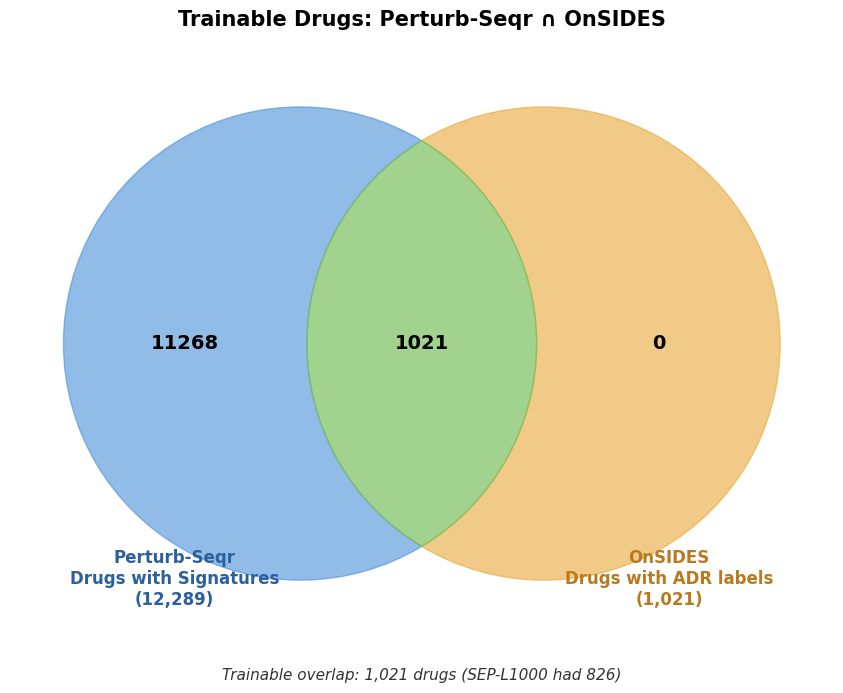

In [7]:
# Venn diagram: Perturb-Seqr drugs vs OnSIDES drugs
fig, ax = plt.subplots(figsize=(10, 7))

v = venn2(
    [all_perturbed_drugs, trainable_names],
    set_labels=("", ""),
    layout_algorithm=DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 0.6)),
    ax=ax,
)
v.get_patch_by_id("10").set_color("#4A90D9")
v.get_patch_by_id("10").set_alpha(0.6)
v.get_patch_by_id("01").set_color("#E8A838")
v.get_patch_by_id("01").set_alpha(0.6)
v.get_patch_by_id("11").set_color("#7ABF5E")
v.get_patch_by_id("11").set_alpha(0.7)
for label_id in ["10", "01", "11"]:
    v.get_label_by_id(label_id).set_fontsize(14)
    v.get_label_by_id(label_id).set_fontweight("bold")

ax.text(0.2, 0.05, f"Perturb-Seqr\nDrugs with Signatures\n({len(all_perturbed_drugs):,})",
        ha="center", fontsize=12, fontweight="bold", color="#2C5F9E", transform=ax.transAxes)
ax.text(0.8, 0.05, f"OnSIDES\nDrugs with ADR labels\n({len(trainable_names):,})",
        ha="center", fontsize=12, fontweight="bold", color="#B87A1E", transform=ax.transAxes)
ax.set_title("Trainable Drugs: Perturb-Seqr ∩ OnSIDES", fontsize=15, fontweight="bold", pad=20)
ax.text(0.5, -0.08, f"Trainable overlap: {len(trainable):,} drugs (SEP-L1000 had 826)",
        ha="center", fontsize=11, style="italic", color="#333", transform=ax.transAxes)

plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_venn.png", dpi=150, bbox_inches="tight")
plt.show()

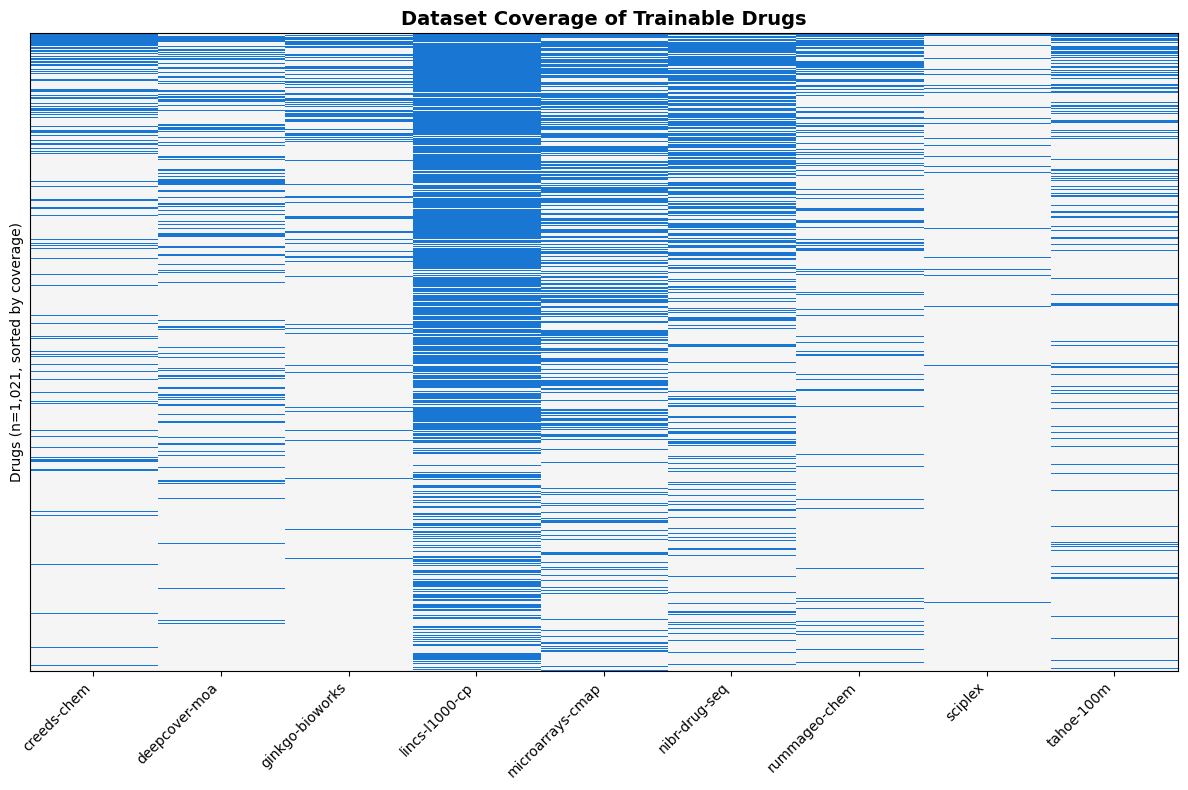


Datasets per trainable drug:
  1 dataset(s): 363 drugs
  2 dataset(s): 296 drugs
  3 dataset(s): 192 drugs
  4 dataset(s): 103 drugs
  5 dataset(s): 41 drugs
  6 dataset(s): 20 drugs
  7 dataset(s): 6 drugs


In [8]:
# Per-dataset coverage heatmap (drug × dataset binary matrix)
datasets_sorted = sorted(per_dataset_drugs.keys())
coverage = pd.DataFrame(
    {ds: [1 if d in per_dataset_drugs[ds] else 0 for d in sorted(trainable)] for ds in datasets_sorted},
    index=sorted(trainable),
)
# Sort drugs by total dataset coverage (most covered first)
coverage["total"] = coverage.sum(axis=1)
coverage = coverage.sort_values("total", ascending=False).drop(columns="total")

fig, ax = plt.subplots(figsize=(12, 8))
cmap = LinearSegmentedColormap.from_list("custom", ["#f5f5f5", "#1976D2"])
ax.imshow(coverage.values, aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_xticks(range(len(coverage.columns)))
ax.set_xticklabels(coverage.columns, rotation=45, ha="right", fontsize=10)
ax.set_ylabel(f"Drugs (n={len(coverage):,}, sorted by coverage)")
ax.set_yticks([])
ax.set_title("Dataset Coverage of Trainable Drugs", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_coverage_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Distribution of dataset counts
n_ds = coverage.sum(axis=1)
print(f"\nDatasets per trainable drug:")
for i in range(1, int(n_ds.max()) + 1):
    count = (n_ds == i).sum()
    if count > 0:
        print(f"  {i} dataset(s): {count:,} drugs")

## Combined Feature Matrix

Build a single drug × gene up/down binary matrix combining all datasets (excluding skipped ones).

In [9]:
X = build_feature_matrix(GMT_DIR, trainable_items=trainable_names, skip_datasets=SKIP_DATASETS, normalize_gene=to_human)
print(f"X shape: {X.shape} (drugs × gene-direction features)")
print(f"Sparsity: {100*(1 - X.values.sum()/np.prod(X.shape)):.1f}%")
print(f"Mean features per drug: {X.sum(axis=1).mean():.0f}")
display(X.iloc[:5, :8])


X shape: (1021, 72294) (drugs × gene-direction features)
Sparsity: 92.0%
Mean features per drug: 5793


,0610007P14RIK_up,0610009B22RIK_up,0610010B08RIK_up,0610010K14RIK_up,0610011F06RIK_up,0610012G03RIK_up,0610025J13RIK_up,0610039K10RIK_up
abacavir,0,0,0,0,0,0,0,0
abemaciclib,0,0,0,0,0,0,0,0
abiraterone,0,0,0,0,0,0,0,0
acalabrutinib,0,0,0,0,0,0,0,0
acamprosate,0,0,0,0,0,0,0,0


## Single ADR Demo: Anaemia

Run the full pipeline on a single target ADR to inspect ROC curve, confusion matrix, and novel predictions. Mirrors the harmonizome-ml `output.ipynb` flow.

In [10]:
# Build target vector for the selected ADR
y = build_target(TARGET_ADR_ID, X, name_to_rxnorm, rxnorm_to_adrs)

print(f"Target: {TARGET_ADR_NAME} (MedDRA {TARGET_ADR_ID})")
print(f"Input shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Class balance: {y.sum()} positive ({100*y.mean():.1f}%), {(y==0).sum()} negative ({100*(1-y.mean()):.1f}%)")

Target: Anaemia (MedDRA 10002034)
Input shape: (1021, 72294)
Target shape: (1021,)
Class balance: 273 positive (26.7%), 748 negative (73.3%)


### ROC Curve

Cross-validated ROC curve. Low fold variance and high AUC indicate a well-generalized model.

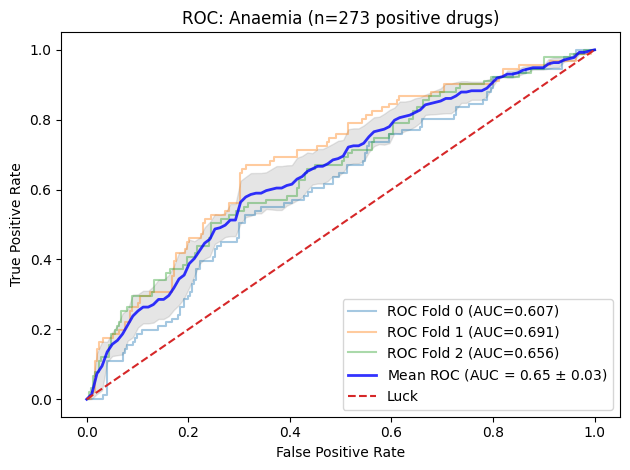

In [11]:
# Run cv_auroc with plot=True to render the ROC curve. The returned CVResult includes
# out-of-fold predictions for the confusion matrix and novel
# predictions table: every prediction is from the CV fold where that drug was held out.
cv_result = cv_auroc(
    X.values, y,
    plot=True,
    plot_title=f"ROC: {TARGET_ADR_NAME} (n={int(y.sum())} positive drugs)",
)
mean_auroc, std_auroc, _, oof_predictions = cv_result

In [12]:
# Statistical significance check
z = (mean_auroc - 0.5) / std_auroc if std_auroc > 0 else float("inf")
cl = sp.stats.norm.cdf(z) * 100
ci = sp.stats.norm.interval(0.95, loc=mean_auroc, scale=std_auroc)
print('Confidence interval (95%):', ci)
print("We are %0.3f %% confident the model's results are not just chance." % cl)
if cl > 95:
    print('Statistically significant. These results can be trusted.')
else:
    print('Not statistically significant. These results should not be trusted.')

Confidence interval (95%): (np.float64(0.5842344438854906), np.float64(0.7183457817790725))
We are 100.000 % confident the model's results are not just chance.
Statistically significant. These results can be trusted.


### Confusion Matrix and Novel Predictions

In [13]:
# Confusion matrix using out-of-fold predictions
y_pred_oof = (oof_predictions > 0.5).astype(int)
cm = metrics.confusion_matrix(y, y_pred_oof)
display(cm)
print(f"\n True negatives:  {cm[0,0]}")
print(f" False positives: {cm[0,1]}")
print(f" False negatives: {cm[1,0]}")
print(f" True positives:  {cm[1,1]}")

array([[740,   8],
       [270,   3]])


 True negatives:  740
 False positives: 8
 False negatives: 270
 True positives:  3


In [14]:
# Uses out-of-fold predictions so each prediction is from a model that never saw that drug
results = pd.DataFrame({
    "Known": y,
    "Predicted": (oof_predictions > 0.5).astype(int),
    "Prediction Probability": oof_predictions,
}, index=X.index)
results.index.name = "Drug"

novel = results[(results["Known"] == 0) & (results["Prediction Probability"] > 0.5)]
print(f"Novel predictions (not in OnSIDES, predicted positive): {len(novel)}")
if len(novel) > 0:
    display(novel.sort_values("Prediction Probability", ascending=False).head(20))
else:
    print("No novel predictions above 0.5 threshold; showing top predictions overall:")
    display(results.sort_values("Prediction Probability", ascending=False).head(20))

Novel predictions (not in OnSIDES, predicted positive): 8


,Known,Predicted,Prediction Probability
Drug,,,
trametinib,0,1,0.560419
vorinostat,0,1,0.556556
hydrocortisone,0,1,0.548007
thioridazine,0,1,0.530145
mebendazole,0,1,0.521783
dexamethasone,0,1,0.521558
mitoxantrone,0,1,0.514647
clofarabine,0,1,0.505100


## Multi-ADR Evaluation (Combined Datasets)

Run the classifier across the top N most common ADRs and report the per-ADR AUROC distribution.

In [15]:
# Filter to ADRs with enough positive examples for meaningful CV (>=50 drugs)
viable_adrs = {adr_id: count for adr_id, count in adr_freq.items() if count >= 50 and adr_id in meddra_names}
top_adrs = sorted(viable_adrs.items(), key=lambda x: -x[1])[:N_TARGETS]
print(f"Evaluating top {len(top_adrs)} ADRs (>=50 positive drugs)...\n")

adr_targets = [
    (adr_id, {"meddra_id": adr_id, "adr_name": meddra_names[adr_id]})
    for adr_id, _ in top_adrs
]
adr_target_builder = lambda aid, X: build_target(aid, X, name_to_rxnorm, rxnorm_to_adrs)

combined_df = evaluate_targets(
    X, adr_target_builder, adr_targets, label_field="adr_name",
).sort_values("auroc", ascending=False)

stats = summarize_aurocs(combined_df)
print(f"\nEvaluated {stats['n']} ADRs")
print(f"Mean AUROC: {stats['mean']:.3f}")
print(f"Median AUROC: {stats['median']:.3f}")
display(combined_df)

Evaluating top 50 ADRs (>=50 positive drugs)...

  Gas: AUROC=0.496 (n=866)
  Nervous: AUROC=0.535 (n=850)
  Nausea: AUROC=0.511 (n=769)
  UTI: AUROC=0.643 (n=770)
  Headache: AUROC=0.563 (n=725)
  Rash: AUROC=0.577 (n=666)
  Gastrointestinal disorder: AUROC=0.621 (n=656)
  Hypersensitivity: AUROC=0.452 (n=643)
  Nervous system disorder: AUROC=0.581 (n=634)
  Vomiting: AUROC=0.577 (n=623)
  Dizziness: AUROC=0.574 (n=590)
  Infection: AUROC=0.650 (n=528)
  Immune system disorder: AUROC=0.528 (n=489)
  Abdominal pain: AUROC=0.622 (n=489)
  Vascular disorder: AUROC=0.568 (n=487)
  Diarrhea: AUROC=0.639 (n=480)
  Fatigue: AUROC=0.624 (n=474)
  Cardiac disorder: AUROC=0.530 (n=473)
  Diarrhoea: AUROC=0.525 (n=463)
  Pain: AUROC=0.611 (n=460)
  Constipation: AUROC=0.634 (n=459)
  Eye disorder: AUROC=0.524 (n=455)
  Pruritus: AUROC=0.575 (n=427)
  Overdose: AUROC=0.680 (n=412)
  Pyrexia: AUROC=0.624 (n=391)
  Cough: AUROC=0.599 (n=370)
  Insomnia: AUROC=0.569 (n=367)
  Arthralgia: AUROC=0.610

,meddra_id,adr_name,n_positive,auroc
23,10033295,Overdose,412,0.679669
43,10043554,Thrombocytopenia,284,0.658629
46,10002034,Anaemia,273,0.651290
11,10021789,Infection,528,0.650440
49,10014210,Edema,261,0.643230
3,10046848,UTI,770,0.642974
15,10012727,Diarrhea,480,0.639341
20,10010774,Constipation,459,0.634357
16,10016256,Fatigue,474,0.624480
24,10037660,Pyrexia,391,0.623700


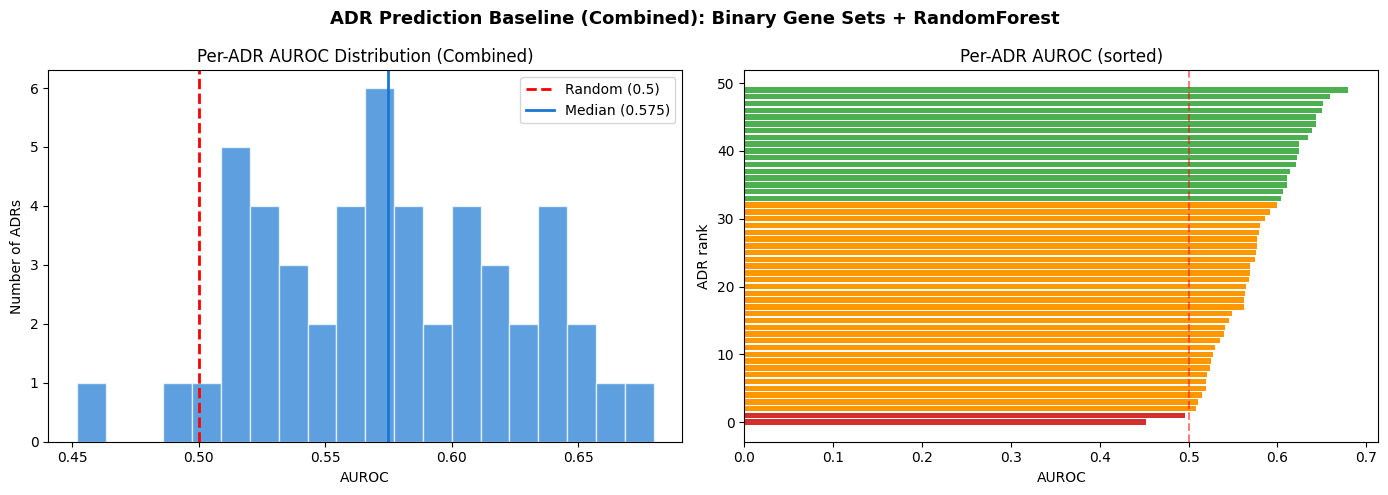


Combined summary:
  ADRs evaluated: 50
  Mean AUROC: 0.576
  Median AUROC: 0.575
  ADRs with AUROC > 0.6: 17
  ADRs with AUROC > 0.7: 0

SEP-L1000 comparison: 0.65–0.85 AUROC range with GO enrichment + chemical structure features


In [16]:
# Visualize AUROC distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(combined_df["auroc"].dropna(), bins=20, color="#1976D2", alpha=0.7, edgecolor="white")
ax1.axvline(x=0.5, color="red", linestyle="--", linewidth=2, label="Random (0.5)")
ax1.axvline(x=combined_df["auroc"].median(), color="#1976D2", linestyle="-", linewidth=2,
            label=f"Median ({combined_df['auroc'].median():.3f})")
ax1.set_xlabel("AUROC")
ax1.set_ylabel("Number of ADRs")
ax1.set_title("Per-ADR AUROC Distribution (Combined)")
ax1.legend()

sorted_combined = combined_df.dropna(subset=["auroc"]).sort_values("auroc")
colors = ["#D32F2F" if x < 0.5 else "#FF9800" if x < 0.6 else "#4CAF50" if x < 0.7 else "#1976D2" for x in sorted_combined["auroc"]]
ax2.barh(range(len(sorted_combined)), sorted_combined["auroc"], color=colors, height=0.8)
ax2.axvline(x=0.5, color="red", linestyle="--", alpha=0.5)
ax2.set_xlabel("AUROC")
ax2.set_ylabel("ADR rank")
ax2.set_title("Per-ADR AUROC (sorted)")

fig.suptitle("ADR Prediction Baseline (Combined): Binary Gene Sets + RandomForest",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_combined_auroc.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nCombined summary:")
print(f"  ADRs evaluated: {len(combined_df)}")
print(f"  Mean AUROC: {combined_df['auroc'].mean():.3f}")
print(f"  Median AUROC: {combined_df['auroc'].median():.3f}")
print(f"  ADRs with AUROC > 0.6: {(combined_df['auroc'] > 0.6).sum()}")
print(f"  ADRs with AUROC > 0.7: {(combined_df['auroc'] > 0.7).sum()}")
print(f"\nSEP-L1000 comparison: 0.65–0.85 AUROC range with GO enrichment + chemical structure features")

## Per-Dataset Evaluation

Run the same classifier independently on each Perturb-Seqr drug perturbation dataset to compare predictive performance across platforms.
To Do: leave-one-out ablation

In [17]:
dataset_results = {}
for gmt_file in sorted(GMT_DIR.glob("*.gmt.gz")):
    dataset = gmt_file.stem.replace(".gmt", "")
    if dataset in SKIP_DATASETS:
        continue

    X_ds = build_feature_matrix(gmt_file, trainable_items=trainable_names, normalize_gene=to_human)
    if X_ds is None or len(X_ds) < 30:
        print(f"{dataset}: only {len(X_ds) if X_ds is not None else 0} drugs, skipping")
        continue

    print(f"\n{'='*60}")
    print(f"{dataset}: {X_ds.shape[0]} drugs × {X_ds.shape[1]} features")
    print(f"{'='*60}")

    df = evaluate_targets(X_ds, adr_target_builder, adr_targets, verbose=False)
    if len(df) == 0:
        print("  No ADRs with enough positive drugs")
        continue
    dataset_results[dataset] = df
    stats = summarize_aurocs(df)
    best = df.loc[df['auroc'].idxmax()]
    print(f"  ADRs evaluated: {stats['n']}")
    print(f"  Mean AUROC: {stats['mean']:.3f}")
    print(f"  Median AUROC: {stats['median']:.3f}")
    print(f"  Best: {best['adr_name']} ({best['auroc']:.3f})")


creeds-chem: 141 drugs × 39374 features
  ADRs evaluated: 50
  Mean AUROC: 0.501
  Median AUROC: 0.495
  Best: Vomiting (0.608)

deepcover-moa: 189 drugs × 12008 features
  ADRs evaluated: 50
  Mean AUROC: 0.515
  Median AUROC: 0.513
  Best: Thrombocytopenia (0.642)

ginkgo-bioworks: 128 drugs × 59058 features
  ADRs evaluated: 50
  Mean AUROC: 0.513
  Median AUROC: 0.499
  Best: Thrombocytopenia (0.635)

lincs-l1000-cp: 714 drugs × 20724 features
  ADRs evaluated: 50
  Mean AUROC: 0.509
  Median AUROC: 0.504
  Best: Thrombocytopenia (0.634)

microarrays-cmap: 414 drugs × 21550 features
  ADRs evaluated: 50
  Mean AUROC: 0.498
  Median AUROC: 0.498
  Best: Myalgia (0.572)

nibr-drug-seq: 362 drugs × 31318 features
  ADRs evaluated: 50
  Mean AUROC: 0.504
  Median AUROC: 0.498
  Best: Vascular disorder (0.576)

rummageo-chem: 161 drugs × 37768 features
  ADRs evaluated: 50
  Mean AUROC: 0.491
  Median AUROC: 0.485
  Best: Edema (0.595)

sciplex: 46 drugs × 18560 features
  ADRs evaluat

## Per-Dataset Comparison

In [18]:
# Summary table: per-dataset stats + combined row
def _row(dataset_name, trainable_count, df):
    stats = summarize_aurocs(df)
    return {
        "Dataset": dataset_name,
        "Trainable drugs": trainable_count,
        "ADRs evaluated": stats["n"],
        "Mean AUROC": stats["mean"],
        "Median AUROC": stats["median"],
        "Max AUROC": stats["max"],
        "> 0.6": stats["above_0.6"],
        "> 0.7": stats["above_0.7"],
    }

summary = [
    _row(ds, len(per_dataset_drugs[ds] & trainable_names), df)
    for ds, df in dataset_results.items()
]
summary.append(_row("ALL COMBINED", len(trainable), combined_df))
summary_df = pd.DataFrame(summary).sort_values("Mean AUROC", ascending=False)
display(summary_df)

,Dataset,Trainable drugs,ADRs evaluated,Mean AUROC,Median AUROC,Max AUROC,> 0.6,> 0.7
9,ALL COMBINED,1021,50,0.575900,0.574931,0.679669,17,0
1,deepcover-moa,189,50,0.514948,0.512587,0.642248,6,0
2,ginkgo-bioworks,128,50,0.512740,0.499451,0.634932,6,0
3,lincs-l1000-cp,714,50,0.509142,0.503925,0.634375,1,0
5,nibr-drug-seq,362,50,0.504192,0.497521,0.575558,0,0
8,tahoe-100m,155,50,0.503544,0.506094,0.688292,1,0
0,creeds-chem,141,50,0.501468,0.494570,0.607937,2,0
4,microarrays-cmap,414,50,0.498178,0.498159,0.571920,0,0
6,rummageo-chem,161,50,0.490820,0.485300,0.595478,0,0
7,sciplex,46,44,0.473352,0.477425,0.659722,6,0


/var/folders/_j/p5822ycn1cbc1q_bcly_5ft80000gn/T/ipykernel_2554/2207072562.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, labels=datasets_for_plot, patch_artist=True, vert=True)


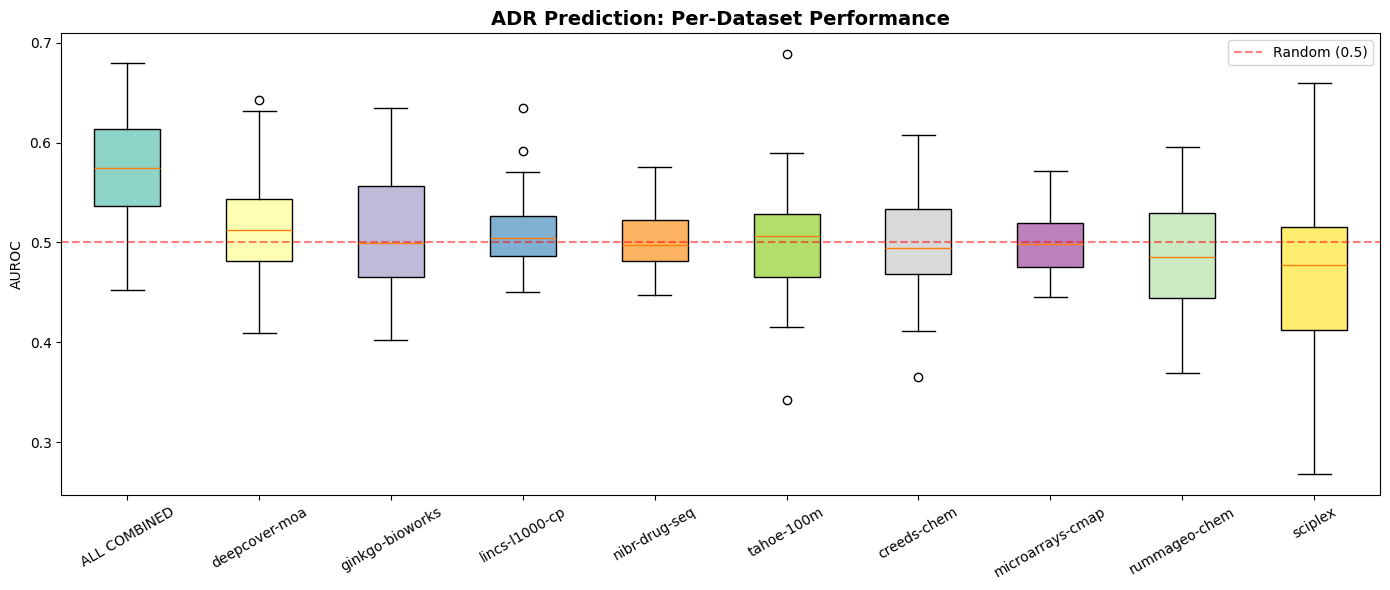

In [19]:
# Box plot comparing AUROC distributions per dataset
fig, ax = plt.subplots(figsize=(14, 6))

datasets_for_plot = summary_df["Dataset"].tolist()
box_data = []
for ds in datasets_for_plot:
    if ds == "ALL COMBINED":
        box_data.append(combined_df["auroc"].dropna().values)
    else:
        box_data.append(dataset_results[ds]["auroc"].dropna().values)

bp = ax.boxplot(box_data, labels=datasets_for_plot, patch_artist=True, vert=True)
colors = plt.cm.Set3(np.linspace(0, 1, len(datasets_for_plot)))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)

ax.axhline(y=0.5, color="red", linestyle="--", alpha=0.5, label="Random (0.5)")
ax.set_ylabel("AUROC")
ax.set_title("ADR Prediction: Per-Dataset Performance", fontsize=14, fontweight="bold")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR / "baseline_per_dataset.png", dpi=150, bbox_inches="tight")
plt.show()